In [ ]:
!pip install -q spacy nltk scikit-learn pandas matplotlib seaborn wordcloud
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 54.4 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
import pandas as pd
import re
import nltk
import spacy
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter
from wordcloud import WordCloud

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

nltk.download('stopwords')
nltk.download('wordnet')

nlp = spacy.load("en_core_web_sm")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving mtsamples.csv to mtsamples.csv


In [ ]:
file_name = list(uploaded.keys())[0]

df = pd.read_csv(file_name)

print("Total rows:",len(df))

df.head()

Total rows: 4999


,Unnamed: 0,description,medical_specialty,sample_name,transcription,keywords
0,0,A 23-year-old white female presents with comp...,Allergy / Immunology,Allergic Rhinitis,"SUBJECTIVE:, This 23-year-old white female pr...","allergy / immunology, allergic rhinitis, aller..."
1,1,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 2,"PAST MEDICAL HISTORY:, He has difficulty climb...","bariatrics, laparoscopic gastric bypass, weigh..."
2,2,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 1,"HISTORY OF PRESENT ILLNESS: , I have seen ABC ...","bariatrics, laparoscopic gastric bypass, heart..."
3,3,2-D M-Mode. Doppler.,Cardiovascular / Pulmonary,2-D Echocardiogram - 1,"2-D M-MODE: , ,1. Left atrial enlargement wit...","cardiovascular / pulmonary, 2-d m-mode, dopple..."
4,4,2-D Echocardiogram,Cardiovascular / Pulmonary,2-D Echocardiogram - 2,1. The left ventricular cavity size and wall ...,"cardiovascular / pulmonary, 2-d, doppler, echo..."


In [ ]:
df = df[['medical_specialty','transcription']]

df.dropna(inplace=True)

print("Rows after cleaning:",len(df))

Rows after cleaning: 4966


In [ ]:
print(df['medical_specialty'].value_counts().head(10))

medical_specialty
Surgery                          1088
Consult - History and Phy.        516
Cardiovascular / Pulmonary        371
Orthopedic                        355
Radiology                         273
General Medicine                  259
Gastroenterology                  224
Neurology                         223
SOAP / Chart / Progress Notes     166
Urology                           156
Name: count, dtype: int64


In [ ]:
top_specialties = df['medical_specialty'].value_counts().head(4).index

df = df[df['medical_specialty'].isin(top_specialties)]

print(df['medical_specialty'].value_counts())

medical_specialty
Surgery                       1088
Consult - History and Phy.     516
Cardiovascular / Pulmonary     371
Orthopedic                     355
Name: count, dtype: int64


In [ ]:
abbrev_dict = {
    "pt":"patient",
    "hx":"history",
    "dx":"diagnosis",
    "tx":"treatment",
    "sx":"symptoms"
}

In [ ]:
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def handle_negation(text):
    text = re.sub(r'\b(no|denies|without)\b', 'NEG', text)
    return text

neg_words = ["no","not","denies","without"]

def clean_text(text):

    text = re.sub(r'[^a-zA-Z ]',' ',text)

    text = text.lower()

    words = text.split()

    expanded = []

    for w in words:
        if w in abbrev_dict:
            expanded.append(abbrev_dict[w])
        else:
            expanded.append(w)

    words = [w for w in expanded if (w not in stop_words or w in neg_words)]

    words = [lemmatizer.lemmatize(w) for w in words]

    return " ".join(words)

In [ ]:
df['transcription'] = df['transcription'].apply(handle_negation)

df['clean_text'] = df['transcription'].apply(clean_text)

df.head()

,medical_specialty,transcription,clean_text
3,Cardiovascular / Pulmonary,"2-D M-MODE: , ,1. Left atrial enlargement wit...",mode left atrial enlargement left atrial diame...
4,Cardiovascular / Pulmonary,1. The left ventricular cavity size and wall ...,left ventricular cavity size wall thickness ap...
7,Cardiovascular / Pulmonary,"2-D ECHOCARDIOGRAM,Multiple views of the heart...",echocardiogram multiple view heart great vesse...
9,Cardiovascular / Pulmonary,"DESCRIPTION:,1. Normal cardiac chambers size....",description normal cardiac chamber size normal...
11,Cardiovascular / Pulmonary,"2-D STUDY,1. Mild aortic stenosis, widely calc...",study mild aortic stenosis widely calcified mi...


In [ ]:
entities = []

for text in df['clean_text']:

    doc = nlp(text)

    for token in doc:

        if token.pos_ == "NOUN":

            entities.append(token.text)

top_entities = Counter(entities).most_common(20)

top_entities

[('patient', 8935),
 ('procedure', 4952),
 ('history', 4346),
 ('pain', 2652),
 ('diagnosis', 2642),
 ('artery', 2573),
 ('incision', 2446),
 ('time', 2338),
 ('year', 2231),
 ('skin', 2058),
 ('room', 1954),
 ('blood', 1824),
 ('suture', 1753),
 ('position', 1624),
 ('area', 1614),
 ('fashion', 1545),
 ('tissue', 1527),
 ('extremity', 1430),
 ('pressure', 1375),
 ('operating', 1332)]

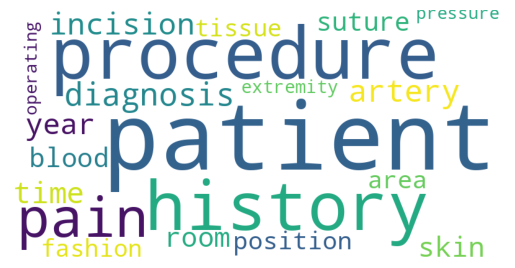

In [ ]:
word_freq = dict(top_entities)

wc = WordCloud(width=800,height=400,background_color='white')

wc.generate_from_frequencies(word_freq)

plt.imshow(wc)

plt.axis("off")

plt.show()

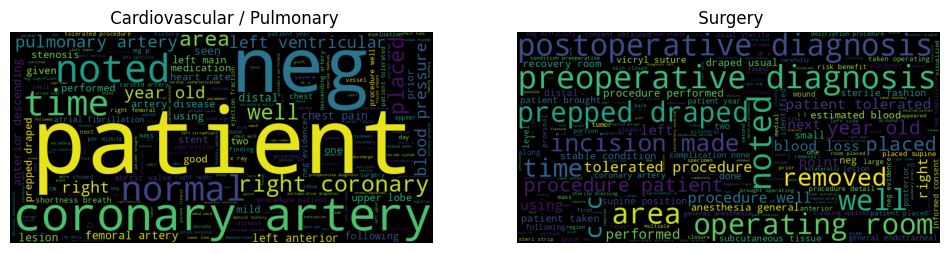

In [ ]:
specialties = df['medical_specialty'].unique()

text1 = " ".join(df[df['medical_specialty']==specialties[0]]['clean_text'])

text2 = " ".join(df[df['medical_specialty']==specialties[1]]['clean_text'])

wc1 = WordCloud(width=800,height=400).generate(text1)
wc2 = WordCloud(width=800,height=400).generate(text2)

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.title(specialties[0])
plt.imshow(wc1)
plt.axis("off")

plt.subplot(1,2,2)
plt.title(specialties[1])
plt.imshow(wc2)
plt.axis("off")

plt.show()

In [ ]:
sentence = df['clean_text'].iloc[0]

doc = nlp(sentence)

for token in doc:
    print(token.text, token.dep_, token.head.text)

spacy.displacy.render(doc, style="dep", jupyter=True)

mode nsubj left
left ROOT left
atrial amod enlargement
enlargement nmod size
left amod size
atrial amod diameter
diameter nmod size
cm nmod size
normal amod size
size nmod ventricle
right advmod left
left amod ventricle
ventricle nmod function
normal amod function
lv nmod function
systolic amod function
function dobj left
left advcl left
ventricular amod fraction
ejection compound fraction
fraction dobj left
normal amod function
lv compound function
diastolic compound function
function oprd left
no det effusion
pericardial amod effusion
effusion nmod valve
normal amod valve
morphology nmod valve
aortic amod valve
valve nmod trace
mitral amod tricuspid
valve compound tricuspid
tricuspid compound valve
valve nmod trace
pulmonary amod valve
valve appos valve
pa nmod doppler
systolic amod pressure
pressure compound mmhg
mmhg compound doppler
doppler nmod trace
mild amod trace
mitral nmod trace
tricuspid nmod trace
regurgitation compound trace
trace nmod regurgitation
aortic amod regurgitat

In [ ]:
neg_words = ["no","not","denies","without"]

def detect_negation(sentence):

    doc = nlp(sentence)

    results = []

    for token in doc:

        if token.pos_ == "NOUN":

            status = "Present"

            for child in token.children:

                if child.text in neg_words:

                    status = "Negated"

            results.append({
                "Entity":token.text,
                "Status":status
            })

    return results

In [ ]:
example = "Patient denies chest pain but has fever"

detect_negation(example)

[{'Entity': 'chest', 'Status': 'Present'},
 {'Entity': 'pain', 'Status': 'Present'},
 {'Entity': 'fever', 'Status': 'Present'}]

In [ ]:
vectorizer=TfidfVectorizer(
    max_features=7000,
    ngram_range=(1,2),
    min_df=2
)

X = vectorizer.fit_transform(df['clean_text'])

y = df['medical_specialty']

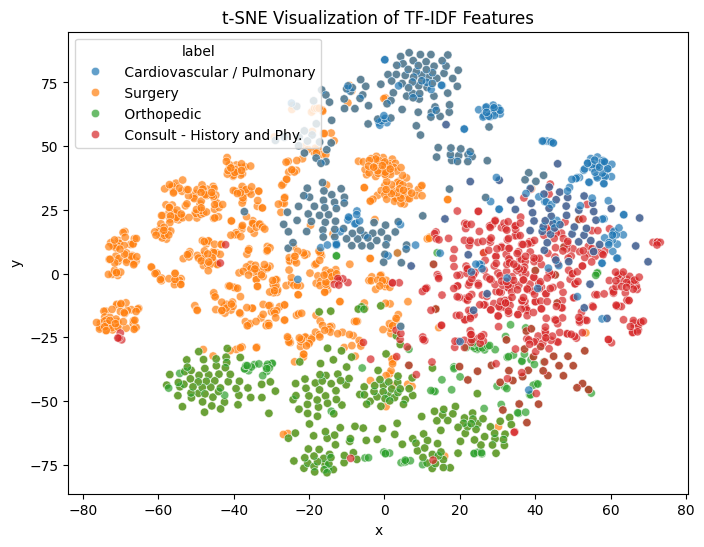

In [ ]:
from sklearn.manifold import TSNE

# Convert sparse → dense
X_dense = X.toarray()

tsne = TSNE(n_components=2, random_state=42, perplexity=30)
X_tsne = tsne.fit_transform(X_dense)

tsne_df = pd.DataFrame({
    'x': X_tsne[:,0],
    'y': X_tsne[:,1],
    'label': y.values
})

plt.figure(figsize=(8,6))

sns.scatterplot(
    x='x',
    y='y',
    hue='label',
    palette='tab10',
    data=tsne_df,
    alpha=0.7
)

plt.title("t-SNE Visualization of TF-IDF Features")
plt.show()

In [ ]:
X_train,X_test,y_train,y_test = train_test_split(
    X,y,test_size=0.2,random_state=42,stratify=y
)

In [ ]:
from sklearn.svm import LinearSVC

model = LinearSVC(C=0.5)

model.fit(X_train,y_train)

LinearSVC(C=0.5)

In [ ]:
model.fit(X_train, y_train)
pred = model.predict(X_test)

accuracy = accuracy_score(y_test,pred)

print("Accuracy:",accuracy)

Accuracy: 0.6030042918454935


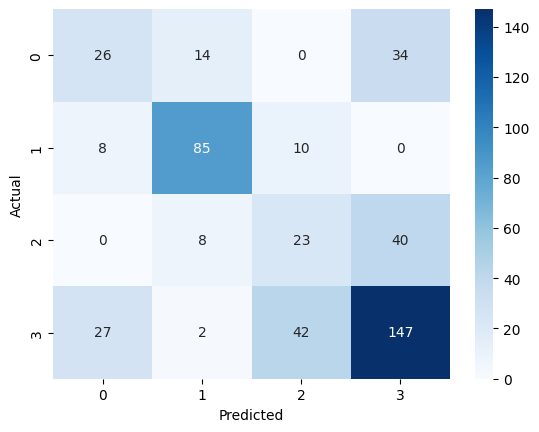

In [ ]:
cm = confusion_matrix(y_test,pred)

sns.heatmap(cm,annot=True,fmt='d',cmap="Blues")

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()